In [1]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

## 1.Collectiong Data

In [2]:
media_engagement=pd.read_csv("social media engagement.csv")
media_engagement

,post_id,platform,post_type,post_time,likes,comments,shares,post_day,sentiment_score
0,1,Facebook,image,8/17/2023 14:45,2121,474,628,Thursday,positive
1,2,Facebook,carousel,5/14/2023 0:45,3660,432,694,Sunday,neutral
2,3,Instagram,poll,2/21/2023 16:15,4955,408,688,Tuesday,negative
3,4,Twitter,image,11/16/2023 0:45,1183,90,187,Thursday,negative
4,5,Twitter,video,5/23/2023 0:30,3499,247,286,Tuesday,positive
...,...,...,...,...,...,...,...,...,...
95,96,Instagram,carousel,07-12-2023 17:45,36,294,911,Wednesday,positive
96,97,Twitter,video,10/27/2023 23:45,314,108,458,Friday,neutral
97,98,Twitter,text,08-05-2023 08:45,229,179,38,Saturday,positive
98,99,Instagram,poll,12/29/2023 12:15,5000,500,204,Friday,positive


## 2. Feature Engineering (Initial Analysis)

In [3]:
media_engagement.shape

(100, 9)

In [4]:
media_engagement.isnull().sum()

post_id            0
platform           0
post_type          0
post_time          0
likes              0
comments           0
shares             0
post_day           0
sentiment_score    0
dtype: int64

In [5]:
media_engagement.describe()

,post_id,likes,comments,shares
count,100.000000,100.000000,100.00000,100.000000
mean,50.500000,2381.810000,202.66000,415.650000
std,29.011492,1632.573284,138.84067,283.877601
min,1.000000,15.000000,10.00000,16.000000
25%,25.750000,895.750000,89.75000,183.000000
50%,50.500000,2220.000000,171.00000,356.500000
75%,75.250000,3593.250000,299.00000,689.500000
max,100.000000,5000.000000,500.00000,993.000000


## 3.Getting Data Types

In [6]:
media_engagement.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   post_id          100 non-null    int64 
 1   platform         100 non-null    object
 2   post_type        100 non-null    object
 3   post_time        100 non-null    object
 4   likes            100 non-null    int64 
 5   comments         100 non-null    int64 
 6   shares           100 non-null    int64 
 7   post_day         100 non-null    object
 8   sentiment_score  100 non-null    object
dtypes: int64(4), object(5)
memory usage: 7.2+ KB


#### 3.1 Transforming post_time dtype to Date time Format

In [7]:
media_engagement["post_time"]=media_engagement["post_time"].str.replace("/","-")
media_engagement

,post_id,platform,post_type,post_time,likes,comments,shares,post_day,sentiment_score
0,1,Facebook,image,8-17-2023 14:45,2121,474,628,Thursday,positive
1,2,Facebook,carousel,5-14-2023 0:45,3660,432,694,Sunday,neutral
2,3,Instagram,poll,2-21-2023 16:15,4955,408,688,Tuesday,negative
3,4,Twitter,image,11-16-2023 0:45,1183,90,187,Thursday,negative
4,5,Twitter,video,5-23-2023 0:30,3499,247,286,Tuesday,positive
...,...,...,...,...,...,...,...,...,...
95,96,Instagram,carousel,07-12-2023 17:45,36,294,911,Wednesday,positive
96,97,Twitter,video,10-27-2023 23:45,314,108,458,Friday,neutral
97,98,Twitter,text,08-05-2023 08:45,229,179,38,Saturday,positive
98,99,Instagram,poll,12-29-2023 12:15,5000,500,204,Friday,positive


In [8]:
media_engagement.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   post_id          100 non-null    int64 
 1   platform         100 non-null    object
 2   post_type        100 non-null    object
 3   post_time        100 non-null    object
 4   likes            100 non-null    int64 
 5   comments         100 non-null    int64 
 6   shares           100 non-null    int64 
 7   post_day         100 non-null    object
 8   sentiment_score  100 non-null    object
dtypes: int64(4), object(5)
memory usage: 7.2+ KB


In [9]:
media_engagement["post_time"] = pd.to_datetime(media_engagement["post_time"],format="%m-%d-%Y %H:%M")
media_engagement

,post_id,platform,post_type,post_time,likes,comments,shares,post_day,sentiment_score
0,1,Facebook,image,2023-08-17 14:45:00,2121,474,628,Thursday,positive
1,2,Facebook,carousel,2023-05-14 00:45:00,3660,432,694,Sunday,neutral
2,3,Instagram,poll,2023-02-21 16:15:00,4955,408,688,Tuesday,negative
3,4,Twitter,image,2023-11-16 00:45:00,1183,90,187,Thursday,negative
4,5,Twitter,video,2023-05-23 00:30:00,3499,247,286,Tuesday,positive
...,...,...,...,...,...,...,...,...,...
95,96,Instagram,carousel,2023-07-12 17:45:00,36,294,911,Wednesday,positive
96,97,Twitter,video,2023-10-27 23:45:00,314,108,458,Friday,neutral
97,98,Twitter,text,2023-08-05 08:45:00,229,179,38,Saturday,positive
98,99,Instagram,poll,2023-12-29 12:15:00,5000,500,204,Friday,positive


## 4.Creating Engagement Rate
* Engagement Rate = like+Comments+Shares

In [10]:
media_engagement["Engagement_rate"]=media_engagement["likes"]+media_engagement["shares"]+media_engagement["comments"]
media_engagement


,post_id,platform,post_type,post_time,likes,comments,shares,post_day,sentiment_score,Engagement_rate
0,1,Facebook,image,2023-08-17 14:45:00,2121,474,628,Thursday,positive,3223
1,2,Facebook,carousel,2023-05-14 00:45:00,3660,432,694,Sunday,neutral,4786
2,3,Instagram,poll,2023-02-21 16:15:00,4955,408,688,Tuesday,negative,6051
3,4,Twitter,image,2023-11-16 00:45:00,1183,90,187,Thursday,negative,1460
4,5,Twitter,video,2023-05-23 00:30:00,3499,247,286,Tuesday,positive,4032
...,...,...,...,...,...,...,...,...,...,...
95,96,Instagram,carousel,2023-07-12 17:45:00,36,294,911,Wednesday,positive,1241
96,97,Twitter,video,2023-10-27 23:45:00,314,108,458,Friday,neutral,880
97,98,Twitter,text,2023-08-05 08:45:00,229,179,38,Saturday,positive,446
98,99,Instagram,poll,2023-12-29 12:15:00,5000,500,204,Friday,positive,5704


#### 4.1 Grouping Engagement_rate by platforms,post_type,post_day

In [11]:
media_engagement.groupby("platform")["Engagement_rate"].mean()

platform
Facebook     3423.031250
Instagram    3757.444444
Twitter      1725.218750
Name: Engagement_rate, dtype: float64

In [12]:
media_engagement.groupby("post_type")["Engagement_rate"].mean()

post_type
carousel    3030.730769
image       2601.470588
poll        3746.384615
text        2228.619048
video       3542.782609
Name: Engagement_rate, dtype: float64

In [13]:
media_engagement.groupby("post_time")["Engagement_rate"].mean()

post_time
2023-01-01 06:00:00    6410.0
2023-01-01 20:00:00    5479.0
2023-01-03 03:00:00    2622.0
2023-01-04 18:30:00    3088.0
2023-01-07 10:30:00    1432.0
                        ...  
2023-12-27 04:00:00    3048.0
2023-12-27 11:30:00    1304.0
2023-12-28 16:45:00    1723.0
2023-12-29 12:15:00    5704.0
2023-12-31 22:30:00    4472.0
Name: Engagement_rate, Length: 99, dtype: float64

In [14]:
media_engagement.groupby('sentiment_score')['Engagement_rate'].mean()

sentiment_score
negative    3598.592593
neutral     2371.222222
positive    3017.978261
Name: Engagement_rate, dtype: float64

#### 4.2 Finding the Correlation

In [15]:
media_engagement[['likes', 'comments', 'shares']].corr()

,likes,comments,shares
likes,1.000000,0.295240,0.244302
comments,0.295240,1.000000,0.254583
shares,0.244302,0.254583,1.000000


## 5.Visualization

In [16]:
import seaborn as sns
from matplotlib import pyplot as plt

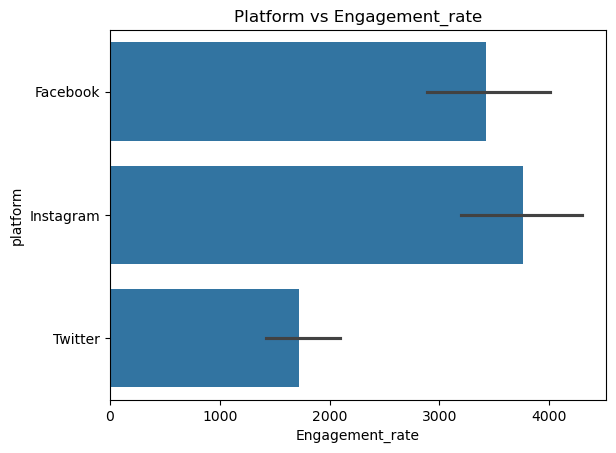

In [17]:
sns.barplot(data=media_engagement,x="Engagement_rate",y="platform")
plt.title("Platform vs Engagement_rate")
plt.show()

#### Insights
* Instagram gets more Engagement score about 3500

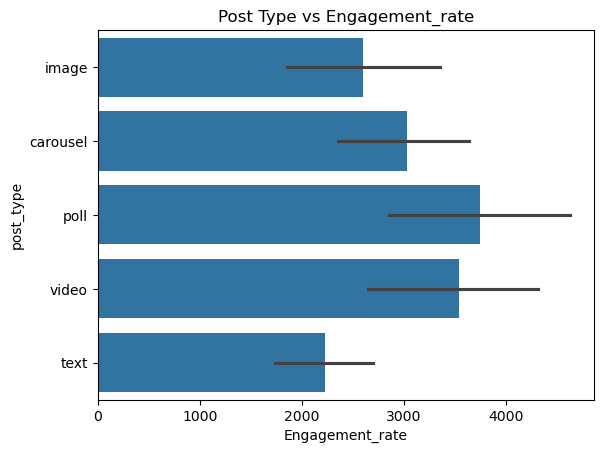

In [18]:
sns.barplot(data=media_engagement,x="Engagement_rate",y="post_type")
plt.title("Post Type vs Engagement_rate")
plt.show()

#### Insights
* Poll gets the highest Engagement score, This shows that the people doesn't just want to scroll the content
* They want to actively participate

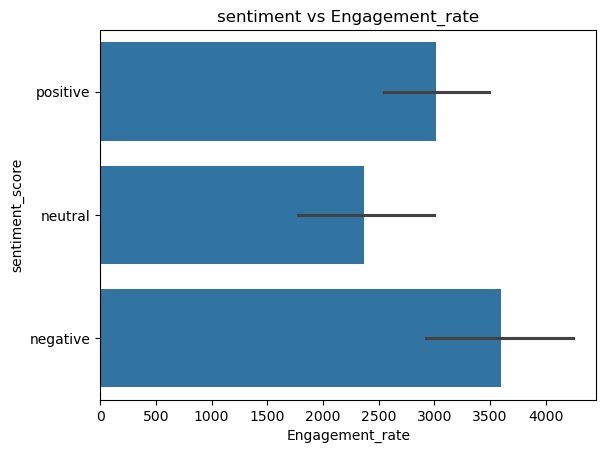

In [19]:
sns.barplot(data=media_engagement,x="Engagement_rate",y="sentiment_score")
plt.title("sentiment vs Engagement_rate")
plt.show()

#### Insights
* Surprisingly, the negative content gets more Engagement rate
* This shows the people are more likely towards the Controversial Contents
* Controversial Content drives people to comment(debate) while Positive content drives people to likes and shares
* Negative sentiment content generates higher engagement, likely due to debate-driven interactions, but may impact long-term audience perception

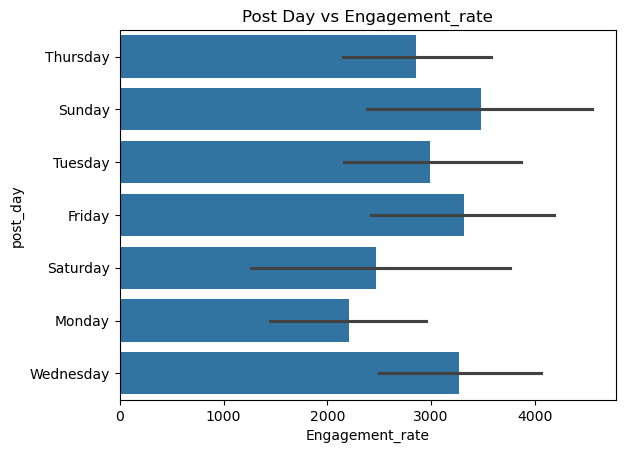

In [20]:
sns.barplot(data=media_engagement,x="Engagement_rate",y="post_day")
plt.title("Post Day vs Engagement_rate")
plt.show()

#### Insights
* Sunday gets the peak Engagement
* Wednesday and Friday gets the peak engagement among week days

## 6.Grouping the Combo

In [21]:
media_engagement.groupby(['platform',"post_type"])['Engagement_rate'].mean()

platform   post_type
Facebook   carousel     3158.000000
           image        1866.500000
           poll         4985.333333
           text         3117.166667
           video        4092.444444
Instagram  carousel     3316.777778
           image        4160.000000
           poll         4325.166667
           text         2330.000000
           video        4862.285714
Twitter    carousel     2481.142857
           image        1273.166667
           poll         1949.000000
           text         1473.500000
           video        1516.571429
Name: Engagement_rate, dtype: float64

In [22]:
media_engagement.groupby(['post_day','post_type'])['Engagement_rate'].mean()

post_day   post_type
Friday     carousel     3610.875000
           image        1955.000000
           poll         5704.000000
           text         2501.000000
           video        3188.000000
Monday     carousel     1677.000000
           image        1930.250000
           text         2417.333333
           video        4289.000000
Saturday   carousel      498.000000
           image        3131.000000
           text         1527.250000
           video        5543.000000
Sunday     carousel     4138.000000
           image        2918.000000
           poll         4884.500000
           text         1079.000000
           video        3289.750000
Thursday   carousel     2559.000000
           image        1767.666667
           poll         2914.000000
           text         3024.000000
           video        3391.833333
Tuesday    carousel     1883.000000
           image        3613.500000
           poll         3861.000000
           text         2321.800000
       

## 7.Time Segmentation

In [23]:
media_engagement["hour"] = media_engagement["post_time"].dt.hour
media_engagement["day"] = media_engagement["post_time"].dt.day_name()


def time_bucket(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

media_engagement["time_bucket"] = media_engagement["hour"].apply(time_bucket)

In [25]:
time_analysis = media_engagement.groupby("time_bucket")["Engagement_rate"].mean().sort_values(ascending=False)
print(time_analysis)

time_bucket
Night        3452.937500
Afternoon    2967.142857
Morning      2759.555556
Evening      2635.000000
Name: Engagement_rate, dtype: float64


## 8.Clustering

In [27]:
from sklearn.preprocessing import StandardScaler

features = media_engagement[["likes", "comments", "shares", "Engagement_rate"]]

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

### 8.1.Applying K means clustering

In [31]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)
media_engagement["cluster"] = kmeans.fit_predict(scaled_features)

cluster_summary = media_engagement.groupby("cluster")[["likes", "comments", "shares", "Engagement_rate"]].mean()
print(cluster_summary)

               likes    comments      shares  Engagement_rate
cluster                                                      
0        2927.333333  127.272727  324.333333      3378.939394
1        4328.320000  335.560000  635.160000      5299.040000
2         794.547619  182.785714  356.738095      1334.071429


C:\Users\shree\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [35]:
best_platform = media_engagement.groupby("platform")["Engagement_rate"].mean().idxmax()
best_content = media_engagement.groupby("post_type")["Engagement_rate"].mean().idxmax()
best_time = media_engagement.groupby("time_bucket")["Engagement_rate"].mean().idxmax()

print([best_platform,best_content, best_time])

['Instagram', 'poll', 'Night']


## 9.Creating a ML Model

#### 9.1 Defining the Target

In [44]:

y = media_engagement["Engagement_rate"]


X = media_engagement.drop(columns=["Engagement_rate", "post_time", "likes", "comments", "shares", "post_id", "cluster"])


#### 9.2 Encoding the Categorical Data

In [45]:
X = pd.get_dummies(X, drop_first=True)

#### 9.3 Train-Test Split

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#### 9.4 Evaluate

In [47]:
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor

# Define and train the model first
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)  # Train the model (assumes X_train and y_train are defined)

# Now predict using the trained model
y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 1258.684
R2 Score: 0.04539392323542191


#### 9.5 Critical Insights

In [53]:
media_engagement["is_weekend"] = media_engagement["post_time"].dt.dayofweek >= 5

media_engagement["engagement_level"] = pd.qcut(
    media_engagement["Engagement_rate"], 
    q=3, 
    labels=["Low", "Medium", "High"]
)

from sklearn.model_selection import GridSearchCV

params = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None]
}

grid = GridSearchCV(RandomForestRegressor(), params, cv=3)
grid.fit(X_train, y_train)

model = grid.best_estimator_


## 10. Advanced ML Pipeline (Added by AI)

In [55]:
import pandas as pd
import numpy as np
import warnings
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt

try:
    from xgboost import XGBRegressor, XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("XGBoost not installed. Falling back to Scikit-Learn models only.")

warnings.filterwarnings('ignore')

# 1. Data Preprocessing
df = pd.read_csv('social media engagement.csv')
df['Engagement_rate'] = df['likes'] + df['shares'] + df['comments']
df = df.drop(columns=['likes', 'comments', 'shares', 'post_id'])
df['post_time'] = pd.to_datetime(df['post_time'].str.replace('/','-'), format='%m-%d-%Y %H:%M')

# 2. Advanced Feature Engineering
df['hour'] = df['post_time'].dt.hour
df['day_of_week'] = df['post_time'].dt.dayofweek
df['is_weekend'] = df['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['is_peak_hour'] = df['hour'].apply(lambda x: 1 if 17 <= x <= 21 else 0)
df['platform_post_type'] = df['platform'] + "_" + df['post_type']
df['platform_is_weekend'] = df['platform'] + "_" + df['is_weekend'].astype(str)

def time_bucket(hour):
    if 5 <= hour < 12: return 'Morning'
    elif 12 <= hour < 17: return 'Afternoon'
    elif 17 <= hour < 21: return 'Evening'
    else: return 'Night'

df['time_bucket'] = df['hour'].apply(time_bucket)
df = df.drop(columns=['post_time', 'hour']) 

# 3. Preprocessing Pipeline Definition
categorical_features = ['platform', 'post_type', 'sentiment_score', 'time_bucket', 'platform_post_type', 'platform_is_weekend']
numerical_features = ['day_of_week', 'is_weekend', 'hour_sin', 'hour_cos', 'is_peak_hour']

y = df['Engagement_rate']
X = df.drop(columns=['Engagement_rate'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# 4. Model Training & Hyperparameter Tuning (Regression)
models_to_train = {
    'RandomForest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'GradientBoosting': GradientBoostingRegressor(random_state=42)
}
if HAS_XGB:
    models_to_train['XGBoost'] = XGBRegressor(random_state=42, objective='reg:squarederror')

param_grids = {
    'RandomForest': {
        'model__n_estimators': [100, 200],
        'model__max_depth': [None, 10, 20],
        'model__min_samples_split': [2, 5]
    },
    'GradientBoosting': {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.01, 0.1],
        'model__max_depth': [3, 5]
    },
    'XGBoost': {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.01, 0.1],
        'model__max_depth': [3, 5],
        'model__subsample': [0.8, 1.0]
    }
}

best_models = {}
results = []
for model_name, model in models_to_train.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    search = RandomizedSearchCV(pipeline, param_distributions=param_grids[model_name], 
                                n_iter=5, cv=3, scoring='neg_mean_absolute_error', 
                                random_state=42, n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[model_name] = search.best_estimator_
    y_pred = search.predict(X_test)
    results.append({'Model': model_name, 'MAE': mean_absolute_error(y_test, y_pred), 'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)), 'R2 Score': r2_score(y_test, y_pred)})

results_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False)
print("=== Regression Model Comparison ===")
print(results_df)

cat_encoder = best_models[results_df.iloc[0]['Model']].named_steps['preprocessor'].transformers_[1][1]
encoded_cat_cols = cat_encoder.get_feature_names_out(categorical_features)
all_feature_names = numerical_features + list(encoded_cat_cols)
if hasattr(best_models[results_df.iloc[0]['Model']].named_steps['model'], 'feature_importances_'):
    importances = best_models[results_df.iloc[0]['Model']].named_steps['model'].feature_importances_
    importance_df = pd.DataFrame({'Feature': all_feature_names, 'Importance': importances})
    print("\n=== Top 10 Drivers of Engagement ===")
    print(importance_df.sort_values(by='Importance', ascending=False).head(10))


XGBoost not installed. Falling back to Scikit-Learn models only.
=== Regression Model Comparison ===
              Model          MAE         RMSE  R2 Score
0      RandomForest  1293.257000  1554.132596  0.094380
1  GradientBoosting  1391.388609  1611.852612  0.025862

=== Top 10 Drivers of Engagement ===
                              Feature  Importance
7                    platform_Twitter    0.272969
2                            hour_sin    0.105089
3                            hour_cos    0.090734
0                         day_of_week    0.061360
21  platform_post_type_Facebook_image    0.035204
14            sentiment_score_neutral    0.032845
11                     post_type_text    0.032343
12                    post_type_video    0.030441
10                     post_type_poll    0.027340
8                  post_type_carousel    0.019685
